In [17]:
# ── Standard library ─────────────────────────────────────────
import os
import re
import string
import pickle
import zipfile
import logging
import urllib.request
import random
from collections import Counter
from pathlib import Path
from typing import Dict, List, Optional, Tuple

# ── Third-party ───────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

# ── NLTK ──────────────────────────────────────────────────────
import nltk
for resource, pkg in [
    ("tokenizers/punkt", "punkt"),
    ("tokenizers/punkt_tab", "punkt_tab"),
    ("corpora/stopwords", "stopwords"),
]:
    try:
        nltk.data.find(resource)
    except LookupError:
        nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords as nltk_stopwords
from nltk.tokenize import word_tokenize

# ── PyTorch ───────────────────────────────────────────────────
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR

# ── Reproducibility ───────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# ── Device ────────────────────────────────────────────────────
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"{'='*55}")
print(f"  PyTorch Version : {torch.__version__}")
print(f"  Device          : {DEVICE}")
if torch.cuda.is_available():
    print(f"  GPU             : {torch.cuda.get_device_name(0)}")
print(f"{'='*55}")

# ── Logging ───────────────────────────────────────────────────
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    datefmt="%H:%M:%S",
    handlers=[
        logging.FileHandler("../training.log", mode="w"),
        logging.StreamHandler()
    ]
)
logger = logging.getLogger("NewsClassifier")

# ── Matplotlib style ──────────────────────────────────────────
plt.style.use("seaborn-v0_8-darkgrid")
COLORS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
print("\n✅ Setup complete.")

  PyTorch Version : 2.12.1+cpu
  Device          : cpu

✅ Setup complete.


In [18]:
# ════════════════════════════════════════════════════════════
#  All hyperparameters and paths in one place
# ════════════════════════════════════════════════════════════

CONFIG = {
    # ── Paths ────────────────────────────────────────────────
    "data_dir"            : Path("../data"),
    "glove_dir"           : Path("../data/glove"),
    "dataset_url"         : "https://huggingface.co/datasets/SetFit/bbc-news/raw/main/bbc-text.csv",
    "dataset_local"       : Path("../data/bbc-text.csv"),
    "glove_url"           : "https://nlp.stanford.edu/data/glove.6B.zip",
    "glove_zip"           : Path("../data/glove/glove.6B.zip"),
    "glove_file"          : Path("../data/glove/glove.6B.100d.txt"),
    "model_save_path"     : Path("../saved_model.pth"),
    "word2idx_save_path"  : Path("../models/word2idx.pkl"),
    "label_enc_save_path" : Path("../models/label_encoder.pkl"),
    "confusion_matrix_path": Path("../models/confusion_matrix.png"),

    # ── Dataset ──────────────────────────────────────────────
    "train_ratio"         : 0.80,
    "val_ratio"           : 0.10,
    "test_ratio"          : 0.10,
    "random_seed"         : SEED,

    # ── Preprocessing ────────────────────────────────────────
    "max_vocab_size"      : 25_000,
    "max_seq_len"         : 512,
    "min_word_freq"       : 2,

    # ── Embeddings ───────────────────────────────────────────
    "embed_dim"           : 100,
    "fine_tune_embeddings": True,

    # ── Model ────────────────────────────────────────────────
    "hidden_size"         : 128,
    "num_layers"          : 2,
    "bidirectional"       : True,
    "lstm_dropout"        : 0.5,
    "fc_dropout"          : 0.3,
    "num_classes"         : 5,

    # ── Training ─────────────────────────────────────────────
    "epochs"              : 20,
    "batch_size"          : 64,
    "learning_rate"       : 1e-3,
    "weight_decay"        : 1e-4,
    "grad_clip"           : 1.0,
    "early_stop_patience" : 5,
    "scheduler_T_max"     : 20,

    # ── Categories ───────────────────────────────────────────
    "label_map"           : {
        "business"      : "Business",
        "entertainment" : "Entertainment",
        "politics"      : "Politics",
        "sport"         : "Sports",
        "tech"          : "Technology",
    },
}

# Create required directories
for key in ["data_dir", "glove_dir"]:
    CONFIG[key].mkdir(parents=True, exist_ok=True)
Path("../models").mkdir(parents=True, exist_ok=True)

print("📋 Configuration loaded.")
for k, v in CONFIG.items():
    print(f"   {k:<25} : {v}")

📋 Configuration loaded.
   data_dir                  : ..\data
   glove_dir                 : ..\data\glove
   dataset_url               : https://huggingface.co/datasets/SetFit/bbc-news/raw/main/bbc-text.csv
   dataset_local             : ..\data\bbc-text.csv
   glove_url                 : https://nlp.stanford.edu/data/glove.6B.zip
   glove_zip                 : ..\data\glove\glove.6B.zip
   glove_file                : ..\data\glove\glove.6B.100d.txt
   model_save_path           : ..\saved_model.pth
   word2idx_save_path        : ..\models\word2idx.pkl
   label_enc_save_path       : ..\models\label_encoder.pkl
   confusion_matrix_path     : ..\models\confusion_matrix.png
   train_ratio               : 0.8
   val_ratio                 : 0.1
   test_ratio                : 0.1
   random_seed               : 42
   max_vocab_size            : 25000
   max_seq_len               : 512
   min_word_freq             : 2
   embed_dim                 : 100
   fine_tune_embeddings      : True
   h

In [19]:
def load_dataset(config: dict) -> pd.DataFrame:
    """Load the BBC News dataset from local cache or remote URL.

    Args:
        config: Project configuration dictionary.

    Returns:
        DataFrame with columns ``['category', 'text', 'label']``.
    """
    local = config["dataset_local"]
    if local.exists():
        logger.info(f"Loading dataset from cache: {local}")
        df = pd.read_csv(local)
    else:
        logger.info(f"Downloading dataset from: {config['dataset_url']}")
        df = pd.read_csv(config["dataset_url"])
        df.to_csv(local, index=False)
        logger.info(f"Dataset cached to: {local}")

    # Normalise column names
    df.columns = [c.strip().lower() for c in df.columns]

    # Map BBC labels → display labels
    df["label"] = df["category"].map(config["label_map"])

    # Drop any rows with missing values
    before = len(df)
    df.dropna(subset=["text", "label"], inplace=True)
    df.reset_index(drop=True, inplace=True)
    logger.info(f"Dataset: {len(df)} rows (dropped {before - len(df)} NaN rows)")

    return df


df = load_dataset(CONFIG)

print(f"\n{'='*50}")
print(f"  Total articles  : {len(df):,}")
print(f"  Columns         : {list(df.columns)}")
print(f"  Categories      : {sorted(df['label'].unique())}")
print(f"{'='*50}")
df.head()

08:26:54 | INFO | Loading dataset from cache: ..\data\bbc-text.csv
08:26:54 | INFO | Dataset: 2225 rows (dropped 0 NaN rows)



  Total articles  : 2,225
  Columns         : ['category', 'text', 'label']
  Categories      : ['Business', 'Entertainment', 'Politics', 'Sports', 'Technology']


,category,text,label
0,tech,tv future in the hands of viewers with home th...,Technology
1,business,worldcom boss left books alone former worldc...,Business
2,sport,tigers wary of farrell gamble leicester say ...,Sports
3,sport,yeading face newcastle in fa cup premiership s...,Sports
4,entertainment,ocean s twelve raids box office ocean s twelve...,Entertainment


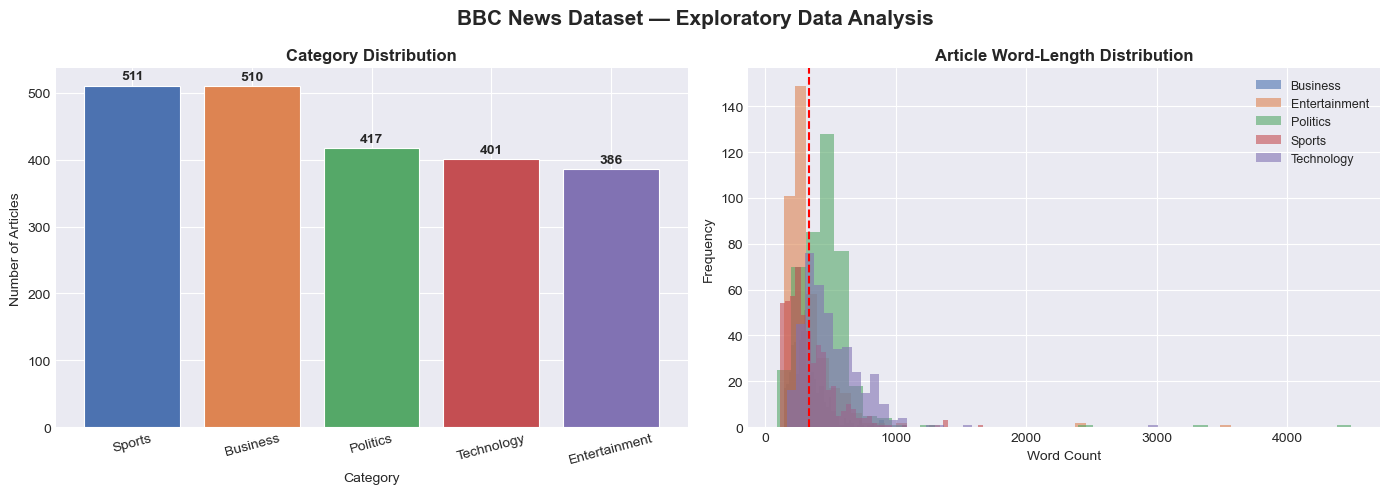


📊 Text length stats:
count    2225.000000
mean      390.295281
std       241.753128
min        90.000000
25%       250.000000
50%       337.000000
75%       479.000000
max      4492.000000


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("BBC News Dataset — Exploratory Data Analysis", fontsize=15, fontweight="bold")

# ── Left: Category Distribution ──────────────────────────────
cat_counts = df["label"].value_counts().sort_values(ascending=False)
bars = axes[0].bar(cat_counts.index, cat_counts.values, color=COLORS, edgecolor="white", linewidth=0.8)
axes[0].set_title("Category Distribution", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Category", fontsize=10)
axes[0].set_ylabel("Number of Articles", fontsize=10)
axes[0].tick_params(axis="x", rotation=15)
for bar, count in zip(bars, cat_counts.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        str(count),
        ha="center", va="bottom", fontsize=10, fontweight="bold"
    )

# ── Right: Text Length Distribution ──────────────────────────
df["text_len"] = df["text"].apply(lambda x: len(x.split()))
for i, (label, group) in enumerate(df.groupby("label")):
    axes[1].hist(group["text_len"], bins=40, alpha=0.6, label=label, color=COLORS[i])
axes[1].set_title("Article Word-Length Distribution", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Word Count", fontsize=10)
axes[1].set_ylabel("Frequency", fontsize=10)
axes[1].legend(fontsize=9)
axes[1].axvline(df["text_len"].median(), color="red", linestyle="--", label=f'Median={df["text_len"].median():.0f}')

plt.tight_layout()
plt.savefig("../models/eda_plots.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\n📊 Text length stats:")
print(df["text_len"].describe().to_string())

In [21]:
STOP_WORDS = set(nltk_stopwords.words("english"))


def clean_text(text: str) -> str:
    """Lowercase, strip URLs, punctuation, digits, and extra spaces."""
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", "", text)       # Remove URLs
    text = text.translate(str.maketrans("", "", string.punctuation))  # Remove punctuation
    text = re.sub(r"\d+", "", text)                           # Remove digits
    text = re.sub(r"\s+", " ", text).strip()                  # Collapse whitespace
    return text


def tokenize_text(text: str, remove_stopwords: bool = True) -> List[str]:
    """Tokenise cleaned text and optionally remove English stopwords."""
    tokens = word_tokenize(text)
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS and len(t) > 1]
    return tokens


def preprocess(text: str) -> List[str]:
    """Full preprocessing: clean → tokenise → remove stopwords."""
    return tokenize_text(clean_text(text))


# Apply preprocessing to the full dataset
print("⏳ Preprocessing all articles ... (may take ~30 seconds)")
df["tokens"] = df["text"].apply(preprocess)
df["token_count"] = df["tokens"].apply(len)

print(f"✅ Done. Example:")
print(f"  Original : {df['text'].iloc[0][:120]}...")
print(f"  Tokens   : {df['tokens'].iloc[0][:20]}")
print(f"\n  Avg tokens per article : {df['token_count'].mean():.0f}")
print(f"  Max tokens per article : {df['token_count'].max()}")

⏳ Preprocessing all articles ... (may take ~30 seconds)
✅ Done. Example:
  Original : tv future in the hands of viewers with home theatre systems  plasma high-definition tvs  and digital video recorders mov...
  Tokens   : ['tv', 'future', 'hands', 'viewers', 'home', 'theatre', 'systems', 'plasma', 'highdefinition', 'tvs', 'digital', 'video', 'recorders', 'moving', 'living', 'room', 'way', 'people', 'watch', 'tv']

  Avg tokens per article : 215
  Max tokens per article : 2187


In [22]:
from sklearn.model_selection import train_test_split

# ── Label Encoding ───────────────────────────────────────────
unique_classes = sorted(df["label"].unique())
STR2IDX: Dict[str, int] = {cls: idx for idx, cls in enumerate(unique_classes)}
IDX2STR: Dict[int, str] = {idx: cls for cls, idx in STR2IDX.items()}
df["encoded_label"] = df["label"].map(STR2IDX)

print(f"📌 Label encoding:")
for cls, idx in STR2IDX.items():
    print(f"   {idx}  →  {cls}")

# ── Stratified Split ─────────────────────────────────────────
train_df, temp_df = train_test_split(
    df, test_size=(1 - CONFIG["train_ratio"]),
    stratify=df["encoded_label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=CONFIG["test_ratio"] / (CONFIG["val_ratio"] + CONFIG["test_ratio"]),
    stratify=temp_df["encoded_label"], random_state=SEED
)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print(f"\n📊 Split sizes:")
print(f"   Train : {len(train_df):>5} ({len(train_df)/len(df)*100:.1f}%)")
print(f"   Val   : {len(val_df):>5} ({len(val_df)/len(df)*100:.1f}%)")
print(f"   Test  : {len(test_df):>5} ({len(test_df)/len(df)*100:.1f}%)")

📌 Label encoding:
   0  →  Business
   1  →  Entertainment
   2  →  Politics
   3  →  Sports
   4  →  Technology

📊 Split sizes:
   Train :  1780 (80.0%)
   Val   :   222 (10.0%)
   Test  :   223 (10.0%)


In [23]:
# Special tokens
PAD_TOKEN, UNK_TOKEN = "<PAD>", "<UNK>"
PAD_IDX,  UNK_IDX   = 0, 1


def build_vocab(
    tokenized_texts: List[List[str]],
    max_vocab_size: int = 25_000,
    min_freq: int = 2,
) -> Dict[str, int]:
    """Build word → index vocabulary from training-set tokens only."""
    counter: Counter = Counter()
    for tokens in tokenized_texts:
        counter.update(tokens)

    vocab_words = [
        word for word, freq in counter.most_common(max_vocab_size)
        if freq >= min_freq
    ]
    word2idx: Dict[str, int] = {PAD_TOKEN: PAD_IDX, UNK_TOKEN: UNK_IDX}
    for word in vocab_words:
        word2idx[word] = len(word2idx)
    return word2idx


def text_to_indices(
    tokens: List[str],
    word2idx: Dict[str, int],
    max_len: int = 512,
) -> List[int]:
    """Convert tokens → padded/truncated index list of fixed length."""
    indices = [word2idx.get(t, UNK_IDX) for t in tokens[:max_len]]
    indices += [PAD_IDX] * (max_len - len(indices))
    return indices


# Build vocabulary from TRAINING set only (to prevent data leakage)
WORD2IDX = build_vocab(
    train_df["tokens"].tolist(),
    max_vocab_size=CONFIG["max_vocab_size"],
    min_freq=CONFIG["min_word_freq"],
)
VOCAB_SIZE = len(WORD2IDX)

print(f"📖 Vocabulary built from training set:")
print(f"   Vocab size       : {VOCAB_SIZE:,}")
print(f"   Max vocab limit  : {CONFIG['max_vocab_size']:,}")
print(f"   Min word freq    : {CONFIG['min_word_freq']}")
print(f"   Sample entries   : { {k: WORD2IDX[k] for k in list(WORD2IDX)[:8]} }")

📖 Vocabulary built from training set:
   Vocab size       : 17,196
   Max vocab limit  : 25,000
   Min word freq    : 2
   Sample entries   : {'<PAD>': 0, '<UNK>': 1, 'said': 2, 'mr': 3, 'would': 4, 'also': 5, 'people': 6, 'new': 7}


In [24]:
def download_glove(config: dict) -> None:
    """Download and extract GloVe 6B if not already present."""
    glove_file = config["glove_file"]
    if glove_file.exists():
        logger.info(f"GloVe already exists: {glove_file}")
        return

    zip_path = config["glove_zip"]
    if not zip_path.exists():
        logger.info(f"Downloading GloVe from {config['glove_url']} (~822 MB) ...")

        def _progress(block: int, block_size: int, total: int) -> None:
            downloaded_mb = block * block_size / 1_048_576
            total_mb = total / 1_048_576
            pct = min(block * block_size / total * 100, 100) if total > 0 else 0
            print(f"\r  ↳ {pct:.1f}%  ({downloaded_mb:.0f} / {total_mb:.0f} MB)", end="", flush=True)

        urllib.request.urlretrieve(config["glove_url"], zip_path, reporthook=_progress)
        print()

    logger.info(f"Extracting {zip_path} ...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(config["glove_dir"])
    logger.info("GloVe extraction complete.")


def load_glove(glove_path: Path, embed_dim: int = 100) -> Dict[str, np.ndarray]:
    """Load GloVe text file into a word→vector dictionary."""
    vectors: Dict[str, np.ndarray] = {}
    with open(glove_path, "r", encoding="utf-8") as f:
        for i, line in enumerate(f):
            parts = line.rstrip().split(" ")
            try:
                vec = np.array(parts[1:], dtype=np.float32)
                if vec.shape[0] == embed_dim:
                    vectors[parts[0]] = vec
            except ValueError:
                continue
            if (i + 1) % 100_000 == 0:
                print(f"\r  ↳ Loaded {i+1:,} lines ...", end="", flush=True)
    print()
    return vectors


def build_embedding_matrix(
    word2idx: Dict[str, int],
    glove_vectors: Dict[str, np.ndarray],
    embed_dim: int = 100,
) -> np.ndarray:
    """Build vocab-aligned embedding matrix; OOV words get random init."""
    rng = np.random.default_rng(SEED)
    vocab_size = len(word2idx)
    matrix = np.zeros((vocab_size, embed_dim), dtype=np.float32)
    found, oov = 0, 0

    for word, idx in word2idx.items():
        if idx == PAD_IDX:
            continue  # PAD stays all-zeros
        if word in glove_vectors:
            matrix[idx] = glove_vectors[word]
            found += 1
        else:
            matrix[idx] = rng.uniform(-0.25, 0.25, embed_dim).astype(np.float32)
            oov += 1

    coverage = found / max(vocab_size - 2, 1) * 100
    logger.info(
        f"Embedding matrix: vocab={vocab_size:,} | "
        f"GloVe hits={found:,} ({coverage:.1f}%) | OOV={oov:,}"
    )
    return matrix


# Download + load
download_glove(CONFIG)
print("\n📦 Loading GloVe vectors ...")
GLOVE_VECTORS = load_glove(CONFIG["glove_file"], embed_dim=CONFIG["embed_dim"])
print(f"   Loaded {len(GLOVE_VECTORS):,} vectors.")

# Build matrix
print("\n🔢 Building embedding matrix ...")
EMBEDDING_MATRIX = build_embedding_matrix(WORD2IDX, GLOVE_VECTORS, CONFIG["embed_dim"])
print(f"   Matrix shape : {EMBEDDING_MATRIX.shape}")

08:26:59 | INFO | GloVe already exists: ..\data\glove\glove.6B.100d.txt



📦 Loading GloVe vectors ...
  ↳ Loaded 400,000 lines ...
   Loaded 400,000 vectors.

🔢 Building embedding matrix ...


08:27:13 | INFO | Embedding matrix: vocab=17,196 | GloVe hits=16,382 (95.3%) | OOV=813


   Matrix shape : (17196, 100)


In [25]:
class NewsDataset(Dataset):
    """PyTorch Dataset for news article classification.

    Args:
        texts:    List of raw text strings.
        labels:   List of integer class indices.
        word2idx: Vocabulary mapping word → index.
        max_len:  Fixed sequence length (padded/truncated).
    """

    def __init__(
        self,
        texts: List[str],
        labels: List[int],
        word2idx: Dict[str, int],
        max_len: int = 512,
    ) -> None:
        self.labels = labels
        self.max_len = max_len
        self.word2idx = word2idx
        # Pre-tokenise & encode all texts
        self.sequences = [
            text_to_indices(preprocess(text), word2idx, max_len)
            for text in texts
        ]

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        seq = torch.tensor(self.sequences[idx], dtype=torch.long)
        lbl = torch.tensor(self.labels[idx], dtype=torch.long)
        return seq, lbl


print("⏳ Building datasets (pre-tokenising all splits) ...")

train_dataset = NewsDataset(
    train_df["text"].tolist(),
    train_df["encoded_label"].tolist(),
    WORD2IDX, CONFIG["max_seq_len"]
)
val_dataset = NewsDataset(
    val_df["text"].tolist(),
    val_df["encoded_label"].tolist(),
    WORD2IDX, CONFIG["max_seq_len"]
)
test_dataset = NewsDataset(
    test_df["text"].tolist(),
    test_df["encoded_label"].tolist(),
    WORD2IDX, CONFIG["max_seq_len"]
)

train_loader = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=CONFIG["batch_size"], shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=CONFIG["batch_size"], shuffle=False, num_workers=0, pin_memory=True)

print(f"✅ DataLoaders ready.")
print(f"   Train batches : {len(train_loader)}")
print(f"   Val   batches : {len(val_loader)}")
print(f"   Test  batches : {len(test_loader)}")

# Quick sanity check
sample_seq, sample_lbl = next(iter(train_loader))
print(f"   Sample batch  : seq={sample_seq.shape}, labels={sample_lbl.shape}")

⏳ Building datasets (pre-tokenising all splits) ...
✅ DataLoaders ready.
   Train batches : 28
   Val   batches : 4
   Test  batches : 4
   Sample batch  : seq=torch.Size([64, 512]), labels=torch.Size([64])


c:\Users\SAYAN\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [26]:
class BiLSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        embed_dim: int = 100,
        hidden_size: int = 128,
        num_layers: int = 2,
        num_classes: int = 5,
        lstm_dropout: float = 0.5,
        fc_dropout: float = 0.3,
        bidirectional: bool = True,
        embedding_matrix: Optional[np.ndarray] = None,
        fine_tune_embeddings: bool = True,
        pad_idx: int = 0,
    ) -> None:
        super().__init__()

        self.bidirectional = bidirectional
        self.hidden_size   = hidden_size
        self.num_layers    = num_layers
        num_directions     = 2 if bidirectional else 1

        # ── Embedding layer ──────────────────────────────────────
        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=pad_idx
        )
        if embedding_matrix is not None:
            self.embedding.weight = nn.Parameter(
                torch.tensor(embedding_matrix, dtype=torch.float32),
                requires_grad=fine_tune_embeddings,
            )

        # ── BiLSTM ───────────────────────────────────────────────
        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            bidirectional=bidirectional,
            dropout=lstm_dropout if num_layers > 1 else 0.0,
            batch_first=True,
        )

        # ── Fully connected head ──────────────────────────────────
        lstm_output_dim = hidden_size * num_directions
        self.dropout1   = nn.Dropout(lstm_dropout)
        self.fc1        = nn.Linear(lstm_output_dim, hidden_size)
        self.relu       = nn.ReLU()
        self.dropout2   = nn.Dropout(fc_dropout)
        self.fc2        = nn.Linear(hidden_size, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Forward pass.

        Args:
            x: LongTensor of shape ``(batch, seq_len)``.

        Returns:
            Raw logits of shape ``(batch, num_classes)``.
        """
        embedded = self.embedding(x)          # (B, L, E)
        _, (hidden, _) = self.lstm(embedded)  # hidden: (num_layers * dirs, B, H)

        # Concatenate last-layer forward + backward hidden states
        if self.bidirectional:
            # hidden[-2] = forward last layer, hidden[-1] = backward last layer
            h = torch.cat((hidden[-2], hidden[-1]), dim=1)  # (B, 2H)
        else:
            h = hidden[-1]                                  # (B, H)

        out = self.dropout1(h)
        out = self.fc1(out)
        out = self.relu(out)
        out = self.dropout2(out)
        out = self.fc2(out)                   # (B, num_classes)
        return out


# ── Instantiate model ────────────────────────────────────────
model = BiLSTMClassifier(
    vocab_size            = VOCAB_SIZE,
    embed_dim             = CONFIG["embed_dim"],
    hidden_size           = CONFIG["hidden_size"],
    num_layers            = CONFIG["num_layers"],
    num_classes           = CONFIG["num_classes"],
    lstm_dropout          = CONFIG["lstm_dropout"],
    fc_dropout            = CONFIG["fc_dropout"],
    bidirectional         = CONFIG["bidirectional"],
    embedding_matrix      = EMBEDDING_MATRIX,
    fine_tune_embeddings  = CONFIG["fine_tune_embeddings"],
    pad_idx               = PAD_IDX,
).to(DEVICE)

# Print model summary
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\n{'='*50}")
print(f"  Total parameters     : {total_params:,}")
print(f"  Trainable parameters : {trainable_params:,}")
print(f"{'='*50}")

BiLSTMClassifier(
  (embedding): Embedding(17196, 100, padding_idx=0)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.5, bidirectional=True)
  (dropout1): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=256, out_features=128, bias=True)
  (relu): ReLU()
  (dropout2): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=5, bias=True)
)

  Total parameters     : 2,383,925
  Trainable parameters : 2,383,925


In [ ]:
from tqdm.notebook import tqdm


def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer,
    grad_clip: float,
) -> Tuple[float, float]:
    """Run one training epoch.

    Returns:
        Tuple of (avg_loss, accuracy).
    """
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for sequences, labels in loader:
        sequences, labels = sequences.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        logits = model(sequences)
        loss = criterion(logits, labels)
        loss.backward()

        # Gradient clipping
        nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()

        total_loss += loss.item() * sequences.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += sequences.size(0)

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
) -> Tuple[float, float]:
    """Evaluate model on a DataLoader.

    Returns:
        Tuple of (avg_loss, accuracy).
    """
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for sequences, labels in loader:
        sequences, labels = sequences.to(DEVICE), labels.to(DEVICE)
        logits = model(sequences)
        loss = criterion(logits, labels)

        total_loss += loss.item() * sequences.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += sequences.size(0)

    return total_loss / total, correct / total


# ── Optimizer, Scheduler, Loss ────────────────────────────────
criterion = nn.CrossEntropyLoss()
optimizer = Adam(
    model.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"]
)
scheduler = CosineAnnealingLR(optimizer, T_max=CONFIG["scheduler_T_max"])

# ── Training history ─────────────────────────────────────────
history = {
    "train_loss": [], "val_loss": [],
    "train_acc":  [], "val_acc":  []
}

# ── Early stopping state ──────────────────────────────────────
best_val_loss  = float("inf")
patience_count = 0

print(f"🚀 Starting training for {CONFIG['epochs']} epochs on {DEVICE} ...\n")
print(f"{'Epoch':>5} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7} | {'LR':>8}")
print("-" * 65)

for epoch in range(1, CONFIG["epochs"] + 1):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, CONFIG["grad_clip"]
    )
    val_loss, val_acc = evaluate(model, val_loader, criterion)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    current_lr = optimizer.param_groups[0]["lr"]
    print(
        f"{epoch:>5} | {train_loss:>10.4f} | {train_acc:>8.2%} | "
        f"{val_loss:>8.4f} | {val_acc:>7.2%} | {current_lr:.2e}"
    )
    logger.info(
        f"Epoch {epoch:02d} | train_loss={train_loss:.4f} train_acc={train_acc:.4f} "
        f"| val_loss={val_loss:.4f} val_acc={val_acc:.4f}"
    )

    # ── Model checkpoint ─────────────────────────────────────
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_count = 0
        torch.save(model.state_dict(), CONFIG["model_save_path"])
        print(f"     ✅ Best model saved (val_loss={val_loss:.4f})")
        logger.info(f"Checkpoint saved at epoch {epoch}")
    else:
        patience_count += 1
        if patience_count >= CONFIG["early_stop_patience"]:
            print(f"\n⛔ Early stopping triggered at epoch {epoch}.")
            logger.info(f"Early stopping at epoch {epoch}")
            break

print(f"\n🏁 Training complete. Best val loss: {best_val_loss:.4f}")

🚀 Starting training for 20 epochs on cpu ...

Epoch | Train Loss | Train Acc | Val Loss | Val Acc |       LR
-----------------------------------------------------------------


08:32:09 | INFO | Epoch 01 | train_loss=1.2438 train_acc=0.5146 | val_loss=0.5179 val_acc=0.7613


    1 |     1.2438 |   51.46% |   0.5179 |  76.13% | 9.94e-04


08:32:10 | INFO | Checkpoint saved at epoch 1


        ✅ Best model saved (val_loss=0.5179)


...

   14 |     0.0041 |   99.94% |   0.1651 |  97.30% | 2.06e-04


09:12:33 | INFO | Epoch 15 | train_loss=0.0050 train_acc=0.9994 | val_loss=0.1424 val_acc=0.9685


   15 |     0.0050 |   99.94% |   0.1424 |  96.85% | 1.46e-04


09:15:43 | INFO | Epoch 16 | train_loss=0.0045 train_acc=0.9994 | val_loss=0.1681 val_acc=0.9685
09:15:43 | INFO | Early stopping at epoch 16


   16 |     0.0045 |   99.94% |   0.1681 |  96.85% | 9.55e-05

⛔ Early stopping triggered at epoch 16.

🏁 Training complete. Best val loss: 0.1354


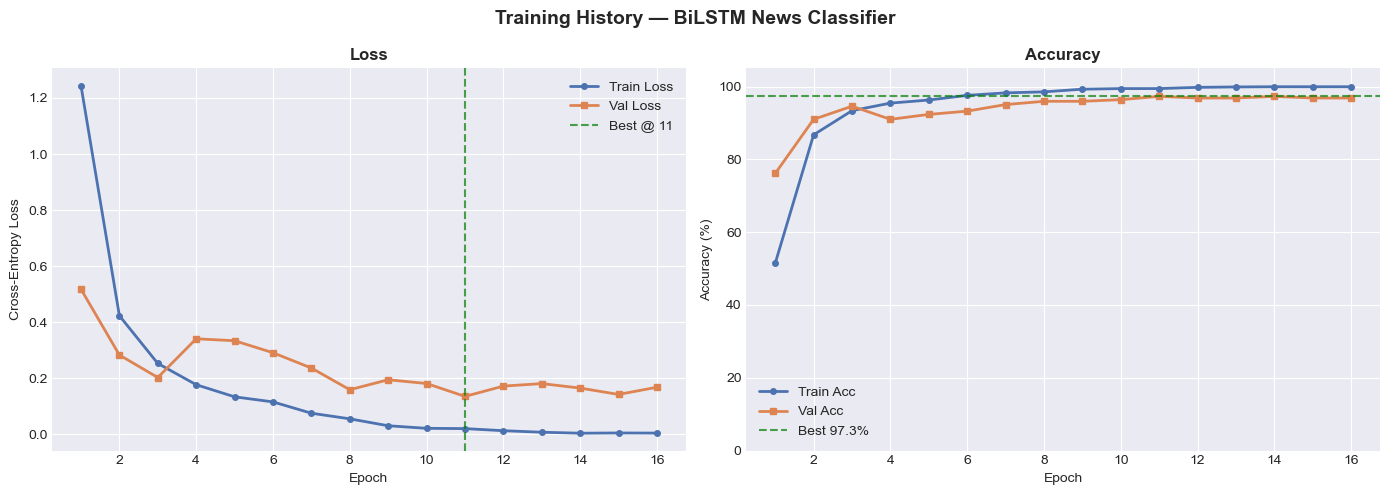

📈 Best validation accuracy : 97.30%
📈 Best epoch               : 11


In [28]:
epochs_ran = list(range(1, len(history["train_loss"]) + 1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Training History — BiLSTM News Classifier", fontsize=14, fontweight="bold")

# ── Loss curves ──────────────────────────────────────────────
axes[0].plot(epochs_ran, history["train_loss"], "o-", color="#4C72B0", label="Train Loss", linewidth=2, markersize=4)
axes[0].plot(epochs_ran, history["val_loss"],   "s-", color="#DD8452", label="Val Loss",   linewidth=2, markersize=4)
axes[0].set_title("Loss", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

best_epoch = history["val_loss"].index(min(history["val_loss"])) + 1
axes[0].axvline(best_epoch, color="green", linestyle="--", alpha=0.7, label=f"Best @ {best_epoch}")
axes[0].legend()

# ── Accuracy curves ───────────────────────────────────────────
axes[1].plot(epochs_ran, [a * 100 for a in history["train_acc"]], "o-", color="#4C72B0", label="Train Acc", linewidth=2, markersize=4)
axes[1].plot(epochs_ran, [a * 100 for a in history["val_acc"]],   "s-", color="#DD8452", label="Val Acc",   linewidth=2, markersize=4)
axes[1].set_title("Accuracy", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim([0, 105])
axes[1].legend()
axes[1].xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

best_val_acc = max(history["val_acc"]) * 100
axes[1].axhline(best_val_acc, color="green", linestyle="--", alpha=0.7, label=f"Best {best_val_acc:.1f}%")
axes[1].legend()

plt.tight_layout()
plt.savefig("../models/training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"📈 Best validation accuracy : {best_val_acc:.2f}%")
print(f"📈 Best epoch               : {best_epoch}")


  TEST SET RESULTS
  Accuracy  : 0.9462  (94.62%)
  Precision : 0.9455
  Recall    : 0.9459
  F1 Score  : 0.9456

📋 Per-class Classification Report:
               precision    recall  f1-score   support

     Business     0.9216    0.9216    0.9216        51
Entertainment     0.9487    0.9487    0.9487        39
     Politics     0.9070    0.9286    0.9176        42
       Sports     1.0000    0.9804    0.9901        51
   Technology     0.9500    0.9500    0.9500        40

     accuracy                         0.9462       223
    macro avg     0.9455    0.9459    0.9456       223
 weighted avg     0.9466    0.9462    0.9464       223



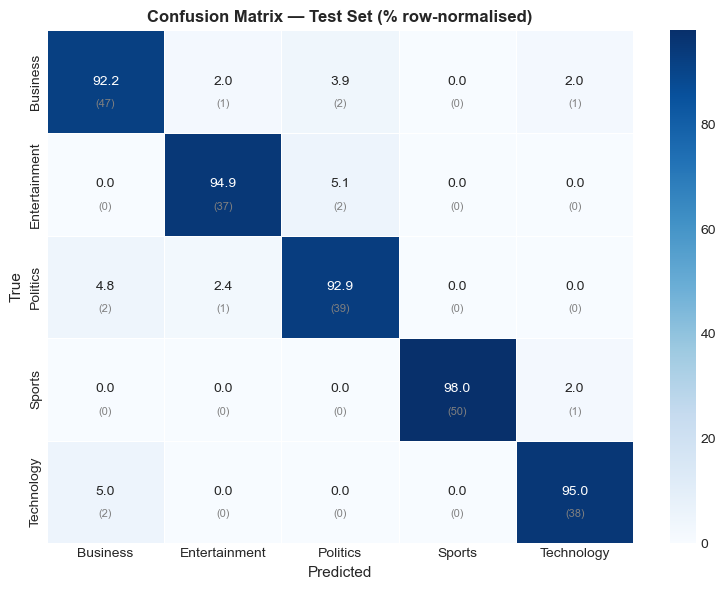

💾 Confusion matrix saved to: ..\models\confusion_matrix.png


In [29]:
# ── Load best checkpoint ─────────────────────────────────────
model.load_state_dict(torch.load(CONFIG["model_save_path"], map_location=DEVICE))
model.eval()


@torch.no_grad()
def get_predictions(
    model: nn.Module, loader: DataLoader
) -> Tuple[List[int], List[int]]:
    """Collect all predictions and ground-truth labels from a DataLoader."""
    all_preds, all_labels = [], []
    for sequences, labels in loader:
        sequences = sequences.to(DEVICE)
        logits = model(sequences)
        preds = logits.argmax(dim=1).cpu().tolist()
        all_preds.extend(preds)
        all_labels.extend(labels.tolist())
    return all_preds, all_labels


test_preds, test_labels = get_predictions(model, test_loader)
class_names = [IDX2STR[i] for i in range(CONFIG["num_classes"])]

# ── Metrics ───────────────────────────────────────────────────
acc  = accuracy_score(test_labels, test_preds)
prec = precision_score(test_labels, test_preds, average="macro")
rec  = recall_score(test_labels, test_preds, average="macro")
f1   = f1_score(test_labels, test_preds, average="macro")

print(f"\n{'='*50}")
print(f"  TEST SET RESULTS")
print(f"{'='*50}")
print(f"  Accuracy  : {acc:.4f}  ({acc*100:.2f}%)")
print(f"  Precision : {prec:.4f}")
print(f"  Recall    : {rec:.4f}")
print(f"  F1 Score  : {f1:.4f}")
print(f"{'='*50}")

print("\n📋 Per-class Classification Report:")
print(classification_report(test_labels, test_preds, target_names=class_names, digits=4))

# ── Confusion Matrix ─────────────────────────────────────────
cm = confusion_matrix(test_labels, test_preds)
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    cm_pct,
    annot=True, fmt=".1f",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues",
    linewidths=0.5,
    ax=ax,
)
# Overlay raw counts
for i in range(len(class_names)):
    for j in range(len(class_names)):
        ax.text(j + 0.5, i + 0.72, f"({cm[i,j]})",
                ha="center", va="center", fontsize=8, color="gray")

ax.set_title("Confusion Matrix — Test Set (% row-normalised)", fontsize=12, fontweight="bold")
ax.set_xlabel("Predicted", fontsize=11)
ax.set_ylabel("True", fontsize=11)
plt.tight_layout()
plt.savefig(CONFIG["confusion_matrix_path"], dpi=150, bbox_inches="tight")
plt.show()
print(f"💾 Confusion matrix saved to: {CONFIG['confusion_matrix_path']}")

## Cell 14 — Predict Function

In [30]:
@torch.no_grad()
def predict(text: str, top_k: int = 5) -> Dict:
    """Classify a news article and return category + confidence scores.

    Args:
        text:  Raw article text string.
        top_k: Number of top predictions to return.

    Returns:
        Dictionary with:
            - ``predicted_category``: Top-1 class label.
            - ``confidence``: Top-1 confidence (%).
            - ``all_scores``: Dict of class → confidence% for all classes.
    """
    model.eval()

    # Preprocess
    tokens  = preprocess(text)
    indices = text_to_indices(tokens, WORD2IDX, CONFIG["max_seq_len"])
    tensor  = torch.tensor([indices], dtype=torch.long).to(DEVICE)

    # Inference
    logits = model(tensor)                      # (1, num_classes)
    probs  = F.softmax(logits, dim=1).squeeze() # (num_classes,)

    top_probs, top_indices = probs.topk(top_k)
    predicted_idx   = top_indices[0].item()
    predicted_class = IDX2STR[predicted_idx]
    confidence      = top_probs[0].item() * 100

    all_scores = {
        IDX2STR[i]: round(probs[i].item() * 100, 2)
        for i in range(CONFIG["num_classes"])
    }

    return {
        "predicted_category": predicted_class,
        "confidence"        : round(confidence, 2),
        "all_scores"        : all_scores,
    }


# ── Example predictions ───────────────────────────────────────
test_articles = [
    "Apple unveiled its newest AI-powered smartphone with a groundbreaking chip architecture.",
    "The Prime Minister announced new economic policies aimed at reducing inflation.",
    "Manchester United secured a dramatic 3-2 victory in the Champions League final.",
    "The Hollywood awards season kicked off with major nominations for blockbuster films.",
    "Global stock markets tumbled as oil prices surged amid supply chain disruptions.",
]

print(f"{'='*65}")
print(f"  EXAMPLE PREDICTIONS")
print(f"{'='*65}")

results = []
for article in test_articles:
    result = predict(article)
    results.append({
        "Article (truncated)": article[:60] + "...",
        "Predicted": result["predicted_category"],
        "Confidence": f"{result['confidence']:.1f}%",
    })
    print(f"\n  📰 {article[:70]}")
    print(f"     → {result['predicted_category']} ({result['confidence']:.1f}%)")
    for cat, score in sorted(result["all_scores"].items(), key=lambda x: -x[1]):
        bar = "█" * int(score / 5)
        print(f"       {cat:<15} {bar:<20} {score:>5.1f}%")

pd.DataFrame(results)

  EXAMPLE PREDICTIONS

  📰 Apple unveiled its newest AI-powered smartphone with a groundbreaking 
     → Technology (99.8%)
       Technology      ███████████████████   99.8%
       Entertainment                          0.1%
       Business                               0.1%
       Politics                               0.0%
       Sports                                 0.0%

  📰 The Prime Minister announced new economic policies aimed at reducing i
     → Politics (98.0%)
       Politics        ███████████████████   98.0%
       Business                               1.9%
       Entertainment                          0.0%
       Sports                                 0.0%
       Technology                             0.0%

  📰 Manchester United secured a dramatic 3-2 victory in the Champions Leag
     → Sports (100.0%)
       Sports          ███████████████████  100.0%
       Business                               0.0%
       Entertainment                          0.0%
       Politic

,Article (truncated),Predicted,Confidence
0,Apple unveiled its newest AI-powered smartphon...,Technology,99.8%
1,The Prime Minister announced new economic poli...,Politics,98.0%
2,Manchester United secured a dramatic 3-2 victo...,Sports,100.0%
3,The Hollywood awards season kicked off with ma...,Entertainment,99.9%
4,Global stock markets tumbled as oil prices sur...,Business,100.0%


## Cell 15 — Save Model Artifacts

In [31]:
import pickle

# ── Save word2idx ─────────────────────────────────────────────
with open(CONFIG["word2idx_save_path"], "wb") as f:
    pickle.dump(WORD2IDX, f)

# ── Save label encoders ───────────────────────────────────────
label_encoder = {"str2idx": STR2IDX, "idx2str": IDX2STR}
with open(CONFIG["label_enc_save_path"], "wb") as f:
    pickle.dump(label_encoder, f)

# ── Save config snapshot ──────────────────────────────────────
config_snapshot = {
    k: str(v) if isinstance(v, Path) else v
    for k, v in CONFIG.items()
}
import json
with open("../models/config_snapshot.json", "w") as f:
    json.dump(config_snapshot, f, indent=2)

print(f"💾 Artifacts saved:")
print(f"   Model       : {CONFIG['model_save_path']}")
print(f"   Vocabulary  : {CONFIG['word2idx_save_path']}")
print(f"   Label enc.  : {CONFIG['label_enc_save_path']}")
print(f"   Config      : ../models/config_snapshot.json")
print(f"   Training log: ../training.log")


💾 Artifacts saved:
   Model       : ..\saved_model.pth
   Vocabulary  : ..\models\word2idx.pkl
   Label enc.  : ..\models\label_encoder.pkl
   Config      : ../models/config_snapshot.json
   Training log: ../training.log
